<p>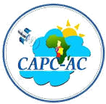&nbsp;&nbsp;&nbsp;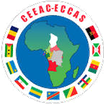</p>

# CAPC-AC ASO 2026 — Central Africa seasonal forecast with acmadDL and africas2s

The Central Africa RCC (CAPC-AC, serving the **ECCAS / CEEAC** region and the
PRESAC forum) August–October 2026 rainfall outlook, built end to end with [`acmadDL`](https://github.com/ACMAD-Niamey/acmadDL) for data,
[`africas2s`](https://github.com/ACMAD-Niamey/africas2s) for statistics and
maps. This is one of five regional demonstration notebooks, one per
continental RCC, all sharing the same structure:

1. **Setup and data** — the region, the model roster, the observations, the
   dry mask and the colour language, and every model's raw forecast;
2. **CCA** — each model calibrated by canonical correlation analysis, the
   equal-weight objective combination, three forecast windows (**ASO, SON,
   OND 2026**) at two working resolutions (**0.5° and 0.1°**);
3. **Skill and expert adjustment** — cross-validated per-model skill maps,
   and the objective re-combined without the lowest-skill model;
4. **Analogue years** — the past years whose El Niño/La Niña evolution most
   resembles this one, and what fell in their ASO seasons;
5. **Onset** — when the rains begin, from the daily forecast streams.

**Season: ASO 2026, from the July 2026 initialisations.** The PRESAC-21
communiqué describes Central Africa as having a unimodal season running
March–October and a bimodal SOND season from September, so August–October
spans the tail of the unimodal rains and the onset of the second bimodal
season — which is why the onset section searches from 1 August rather than
in spring. The three forecast windows slide forward from the season: ASO,
SON and OND 2026, all from the same 1 July initialisation.

### 0. Preliminaries

#### 0.1 Imports

Everything imported once, up front. `acmaddl` is the data layer (one
`fetch()` over every provider, returning normalised xarray with
`lat`/`lon`/`year`/`member` coordinates and known units); `africas2s` is the
statistics and plotting layer. This notebook defines **no plotting functions
and no colour ramps** of its own — every map is drawn through the packaged
RCC display styles.

The C3S seasonal datasets are served by the Copernicus CDS
(`https://cds.climate.copernicus.eu/api`); make sure your `~/.cdsapirc` points
there (see the README prerequisites).

In [1]:
import os
import warnings
warnings.filterwarnings("ignore", message="Degrees of freedom")
import datetime as dt
from dataclasses import replace
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

os.environ.setdefault("CDSAPI_URL", "https://cds.climate.copernicus.eu/api")

import acmaddl
import africas2s
from africas2s import FieldScale
from africas2s import aggregations as agg

warnings.filterwarnings("ignore", message="All-NaN slice encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="daily data starts")   # daily fields begin 2 days after init
warnings.filterwarnings("ignore", message="daily data ends")     # dry-spell guard runs to the data edge
try:  # executed-notebook hygiene: don't tight-crop cartopy figures
    get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except NameError:
    pass

FIG = Path("outputs/CAPC_AC_ASO2026")
FIG.mkdir(parents=True, exist_ok=True)

### 1. Setup and data

#### 1.1 Parameters

The forecast: **ASO 2026 from the July 2026 initialisation**, over the ECCAS
domain CAPC-AC serves. The country list is the member states plus Angola and Chad, which the PRESAC-21 communiqué describes
as part of the domain; several countries appear twice because Natural Earth
and the WMO spell them differently, and the country clip matches on any of
the spellings. Two working resolutions run through the whole notebook:
**0.5°** — the operational grid the RCC products use — and **0.1° (~10 km)**,
the high-resolution leg.

Three forecast **windows** slide forward from the season: ASO, SON and OND
2026, every one from the same `2026-07` initialisation, so the reader sees
the forecast evolve across the lead times of a single issuance.

*The dry mask is a parameter.* A cell is greyed where the season contributes
less than `DRY_SHARE` of its annual rainfall — ICPAC's seasonal-share rule,
inherited by the whole notebook family. A 15 % threshold is used here, in the style of ICPAC's seasonal
products; change the one number below and every map
follows. It is a display choice applied by the style, never a change to the
calculation — and for ASO it removes little or nothing of the ECCAS domain
(§1.5 prints the count): August–October is rainy season almost everywhere
here, northern Chad included.

In [2]:
ECCAS_COUNTRIES = [
    "Angola", "Burundi", "Cameroon", "Central African Republic", "Chad",
    "Republic of the Congo", "Congo", "Democratic Republic of the Congo",
    "Dem. Rep. Congo", "Equatorial Guinea", "Gabon", "Rwanda",
    "São Tomé and Principe", "Sao Tome and Principe",
]
ECCAS_REGION = (-18.0, 24.0, 6.0, 32.0)   # lat_s, lat_n, lon_w, lon_e
EXTENT       = (ECCAS_REGION[2], ECCAS_REGION[3], ECCAS_REGION[0], ECCAS_REGION[1])

SEASON       = "ASO"                      # the target season (first window)
WINDOWS      = ["ASO", "SON", "OND"]      # the three forecast windows, same init
SEASON_DAYS  = 31 + 30 + 31               # Aug + Sep + Oct
INIT_MONTH   = "2026-07"                  # 1 July 2026 initialisations
YEAR         = 2026

RES_LO = 0.5                              # operational grid
RES_HI = 0.1                              # high-resolution leg (~10 km)

DRY_SHARE = 0.15                          # share of annual rainfall below which a cell is greyed

#### 1.2 The model roster

The 10-system base roster shared by the whole notebook family: five NMME
systems (IRI/CCSR, no credentials) and five C3S systems (Copernicus CDS).
Each row is `(label, acmadDL product, hindcast window)`; the window is the
model's native reforecast period clipped to **1993–2020**, so every CCA is
trained on the years that model actually has.

Real-time availability drifts from month to month — a model may have a full
hindcast and no July 2026 forecast yet, or serve an all-fill field for one
target — so the roster is a *request*, and the fetch below reports which
models actually made it in and why the others did not. Two rows need a word
for this cycle:

- **GFDL-SPEAR issues quarterly in 2026** (January, April, July, October).
  July is one of its issuance months, so SPEAR is *present* for this
  forecast — the same row must be dropped for any init month between the
  quarters.
- **JMA is CPS4, not CPS3.** C3S retired system 3 in favour of system 4
  around January 2026; the roster therefore points at `c3s/jma-cps4` for the
  2026 initialisations, with the same 1993–2020 reforecast window.

**Why the hindcast windows differ between models.** They differ *by design*, for one of two reasons:
**what the archive holds** — NASA-GEOSS2S's hindcast ends in 2017 and
ECMWF's in 2016, so those are hard stops — or **a harmonisation choice**:
the roster is floored at **1993**, the year every C3S reforecast begins, so
the NMME systems are not trained on years their C3S counterparts cannot
match. A model whose range looks short against its neighbour's is showing
one of those two things, not missing data. The §1.4 coverage bars below show
the same picture visually.

In [3]:
MODELS = [
    ("CanSIPS-IC4",      "nmme/cansipsic4",   (1993, 2020)),
    ("NASA-GEOSS2S",     "nmme/geoss2s",      (1993, 2017)),
    ("GFDL-SPEAR",       "nmme/spear",        (1993, 2020)),   # quarterly in 2026; July is an issuance month
    ("COLA-RSMAS-CCSM4", "nmme/ccsm4",        (1993, 2020)),
    ("NCEP-CFSv2",       "nmme/cfsv2",        (1993, 2020)),
    ("ECMWF",            "c3s/ecmwf-monthly", (1993, 2016)),
    ("CMCC",             "c3s/cmcc-sps4",     (1993, 2020)),
    ("DWD",              "c3s/dwd",           (1993, 2020)),
    ("JMA",              "c3s/jma-cps4",      (1993, 2020)),
    ("Meteo_France",     "c3s/meteofrance",   (1993, 2020)),
]

CCA needs a **wide** predictor field — the whole tropical belt — because its
value is finding a remote pattern that leads local rainfall; the predictand
stays the ECCAS box. `acmaddl.assemble` returns each model as a
`(hindcast, forecast)` pair of `(year, member, lat, lon)` seasonal fields,
the shape `africas2s` consumes; one assemble per model per window, and the
same pairs feed both the raw-anomaly matrix below and the CCA section.

A provider can answer a request with a field that is structurally fine but
empty in substance — every cell a fill value, every cell zero, a few absurd
numbers — and *which* model does so changes from month to month.
`acmaddl.usable` is the per-field guard: it strips fill and non-finite
cells, then requires what remains to be non-empty, not all zero, and within
the plausible range for precipitation. A model that fails it, or whose
forecast is not yet available, is dropped **with a stated reason** rather
than let into the calibration.

In [4]:
CCA_DOMAIN = (-30.0, 30.0, -180.0, 180.0)   # lat_s, lat_n, lon_w, lon_e

models, dropped = {w: {} for w in WINDOWS}, {w: [] for w in WINDOWS}
for label, product, window in MODELS:
    for w in WINDOWS:
        try:
            pair = acmaddl.assemble([(label, product, window)], "precip",
                                    init=INIT_MONTH, target=w,
                                    region=list(CCA_DOMAIN), seasonal="mean",
                                    boundary="center", verbose=False)[label]
            if not all(acmaddl.usable(x, variable="precip") for x in pair):
                raise ValueError("field is empty or implausible after removing fill")
            models[w][label] = pair
        except Exception as e:
            dropped[w].append(f"{label}: {type(e).__name__}: {str(e)[:70]}")
for w in WINDOWS:
    for line in dropped[w]:
        print(f"dropped [{w}] ", line)
    print(f"{w}: {len(models[w])} of {len(MODELS)} models available: {sorted(models[w])}")

ASO: 10 of 10 models available: ['CMCC', 'COLA-RSMAS-CCSM4', 'CanSIPS-IC4', 'DWD', 'ECMWF', 'GFDL-SPEAR', 'JMA', 'Meteo_France', 'NASA-GEOSS2S', 'NCEP-CFSv2']
SON: 10 of 10 models available: ['CMCC', 'COLA-RSMAS-CCSM4', 'CanSIPS-IC4', 'DWD', 'ECMWF', 'GFDL-SPEAR', 'JMA', 'Meteo_France', 'NASA-GEOSS2S', 'NCEP-CFSv2']
OND: 10 of 10 models available: ['CMCC', 'COLA-RSMAS-CCSM4', 'CanSIPS-IC4', 'DWD', 'ECMWF', 'GFDL-SPEAR', 'JMA', 'Meteo_France', 'NASA-GEOSS2S', 'NCEP-CFSv2']


#### 1.3 Observations

CHIRPS v2 monthly rainfall, averaged over each forecast window for every
year 1982–2020, on both working grids (`seasonal="mean"` gives the mean
monthly total for the season, in mm/month; `boundary="cover"` keeps every cell the region
touches). This is the predictand every CCA is trained against and the record
the analogue section reads from. The annual total (same grid, averaged over
years) is what the dry-season share is measured against.

In [5]:
obs_lo, obs_hi = {}, {}
for w in WINDOWS:
    for res, store in ((RES_LO, obs_lo), (RES_HI, obs_hi)):
        store[w] = acmaddl.fetch("obs/chirps-v2-monthly", "precip", target=w,
                                 region=list(ECCAS_REGION), hindcast=(1982, 2020),
                                 seasonal="mean", grid_res=res, boundary="cover",
                                 verbose=False)["precip"]
print({w: dict(obs_lo[w].sizes) for w in WINDOWS}, "(0.5°)")
print({w: dict(obs_hi[w].sizes) for w in WINDOWS}, "(0.1°)")

annual_lo = acmaddl.fetch("obs/chirps-v2-annual", "precip", region=list(ECCAS_REGION),
                          hindcast=(1982, 2020), grid_res=RES_LO, boundary="cover",
                          verbose=False)["precip"]
annual_lo = annual_lo.mean([d for d in annual_lo.dims if d not in ("lat", "lon")])

{'ASO': {'year': 39, 'lat': 85, 'lon': 53}, 'SON': {'year': 39, 'lat': 85, 'lon': 53}, 'OND': {'year': 39, 'lat': 85, 'lon': 53}} (0.5°)
{'ASO': {'year': 39, 'lat': 421, 'lon': 261}, 'SON': {'year': 39, 'lat': 421, 'lon': 261}, 'OND': {'year': 39, 'lat': 421, 'lon': 261}} (0.1°)


#### 1.4 The acmadDL inventory

The roster and observations above are a *selection* from acmadDL's
catalogue, and the catalogue renders itself as a reference sheet — one row
per product with its source, variables, resolution, cadence, and a
**temporal-coverage bar** on a shared year axis. Forecast systems on the
left, observed products on the right.

This is the fastest way to answer the question that bites hardest when
assembling a multi-model roster: *what years does each product actually
have?* The bars show it directly — GEOSS2S's hindcast ending in 2017 against
ECMWF's 2016, the forecast streams' arrow caps marking an ongoing real-time
record — and on the observations side the CHIRPS family (monthly and annual
here, daily for §5's onset climatology) beside the SST records driving §4's
analogue analysis. Products beyond this notebook's roster are visible
alongside, which is also how you find the next model to add.

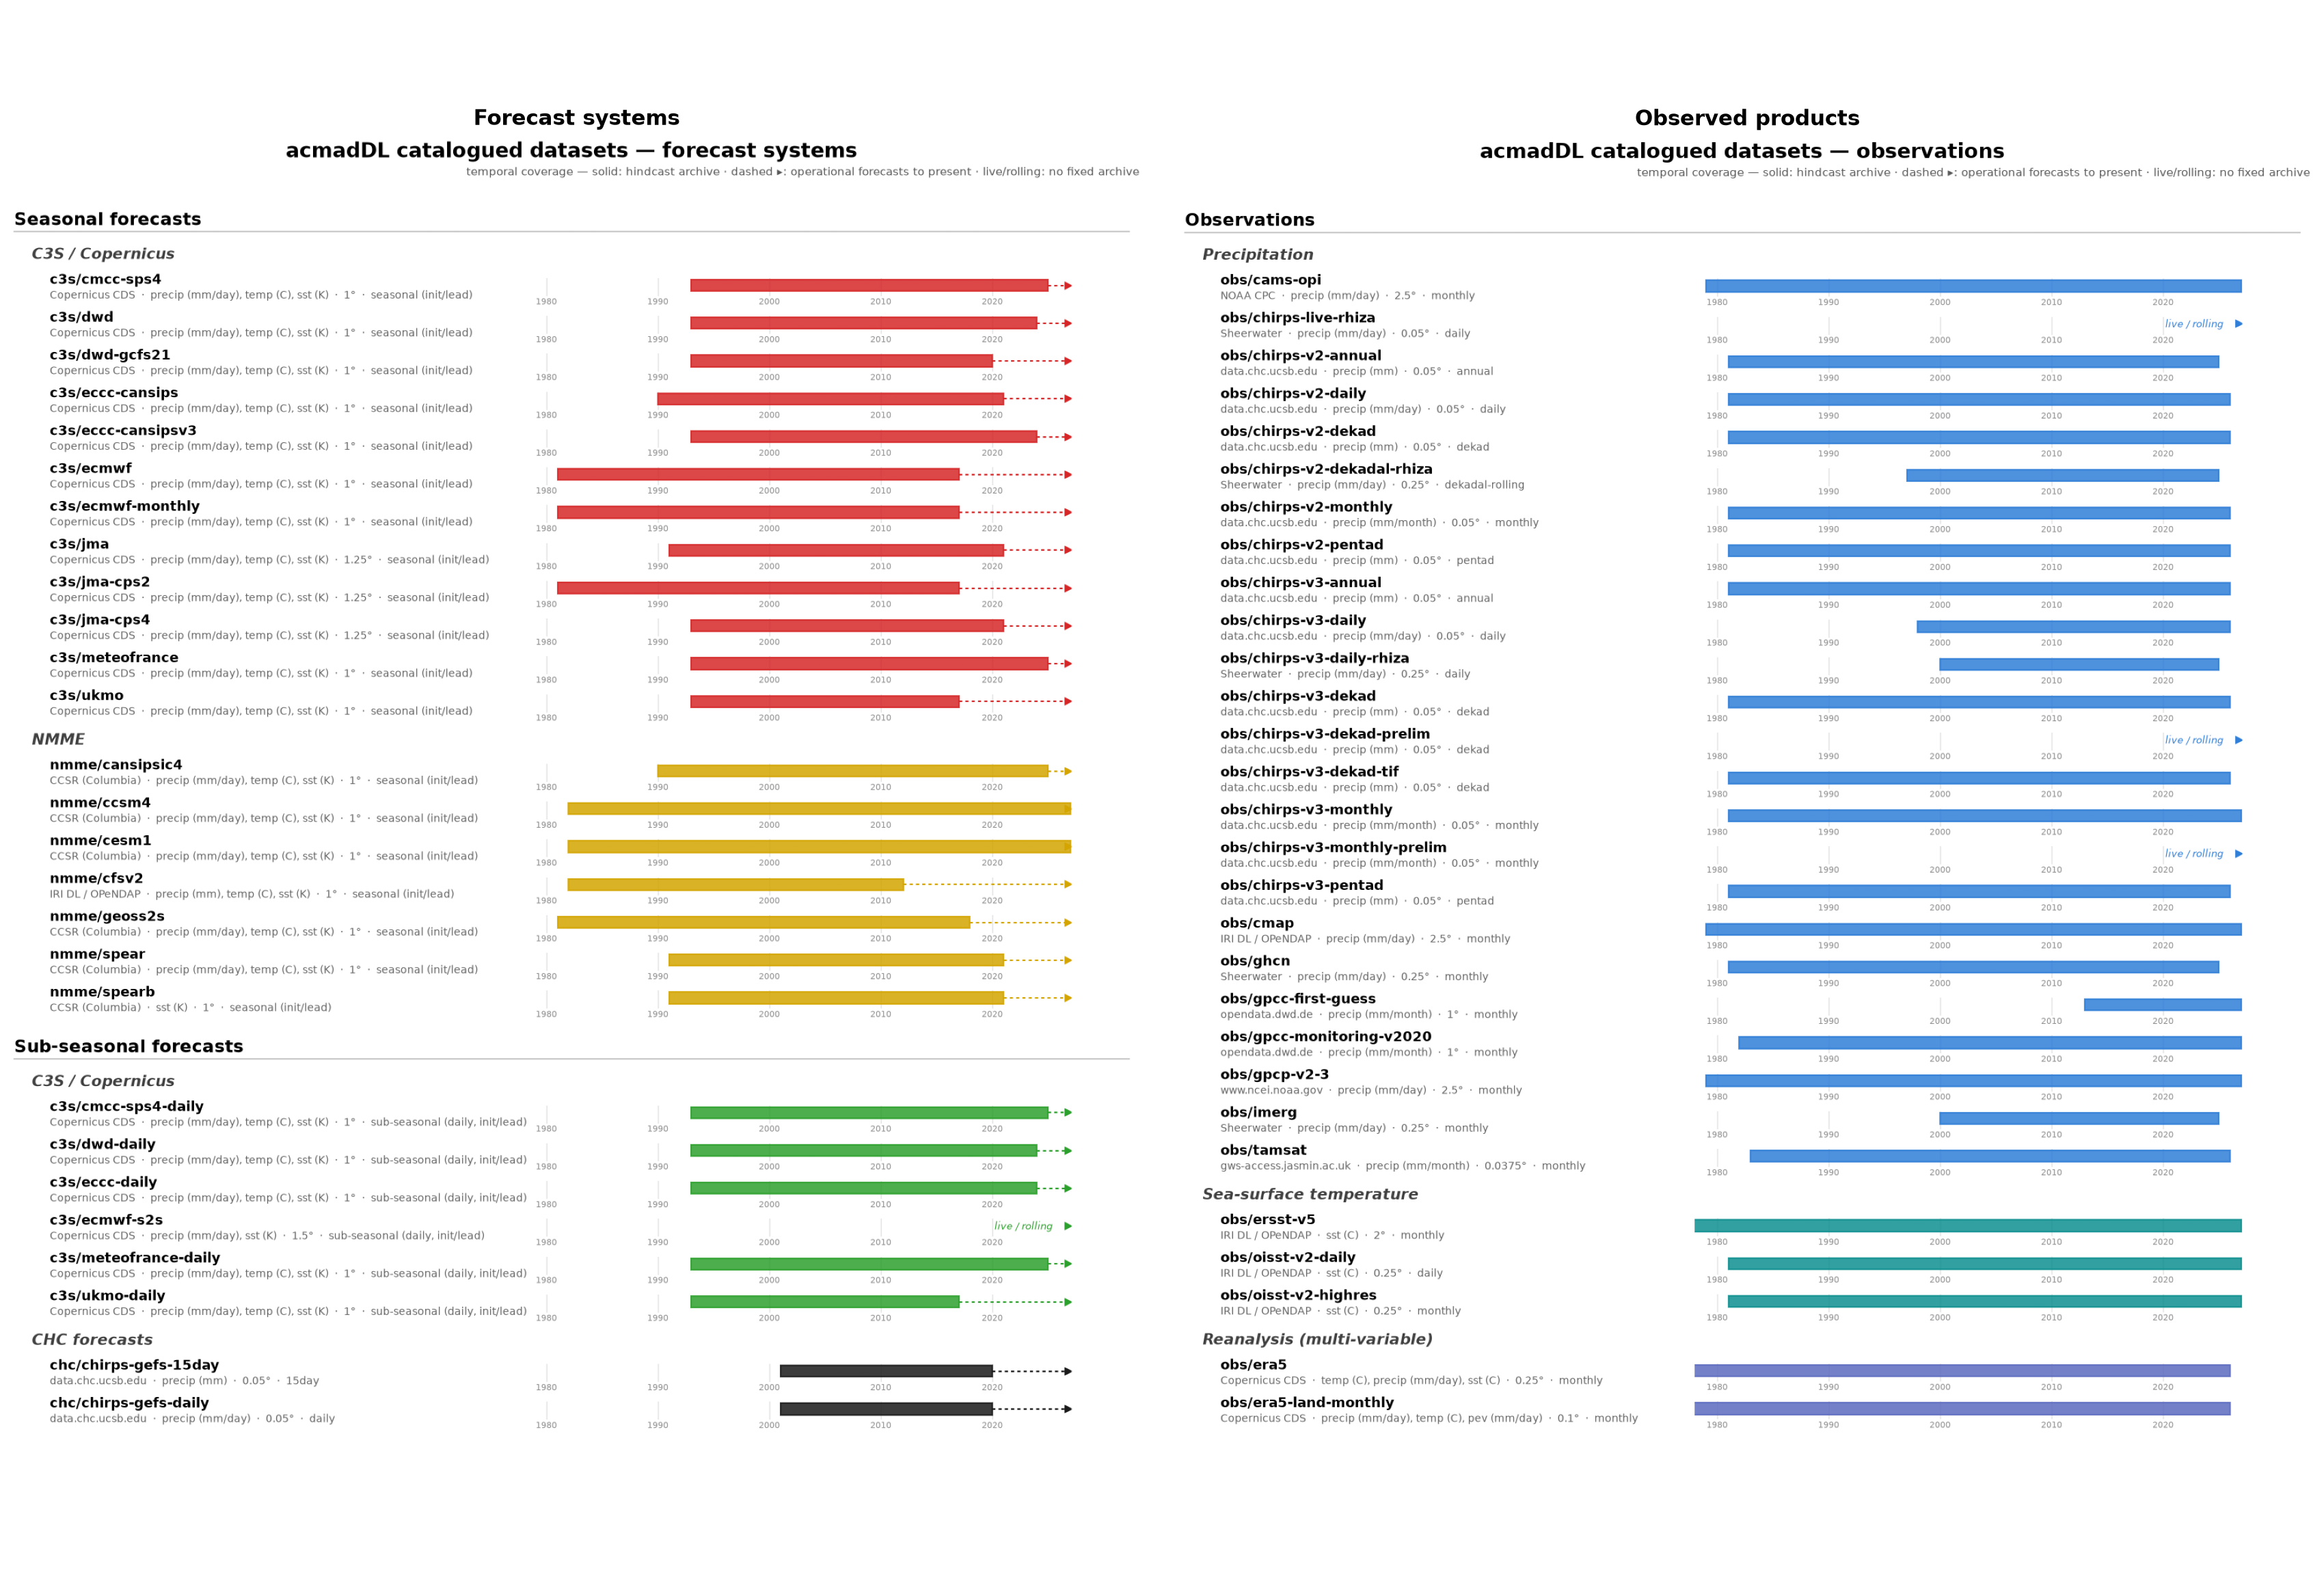

In [6]:
_inv = [acmaddl.show_datasets("forecasts", save=FIG / "_inventory_forecasts.png"),
        acmaddl.show_datasets("observations", save=FIG / "_inventory_observations.png")]
plt.close("all")                       # the sheets are composed side by side below

fig, axes = plt.subplots(1, 2, figsize=(34, 23), layout="constrained")
for ax, (path, title) in zip(axes, [
        (FIG / "_inventory_forecasts.png", "Forecast systems"),
        (FIG / "_inventory_observations.png", "Observed products")]):
    ax.imshow(plt.imread(path))
    ax.set_title(title, fontsize=22, fontweight="bold")
    ax.axis("off")
plt.savefig(FIG / "01b_acmaddl_inventory.png", dpi=170, bbox_inches="tight")
plt.show()

#### 1.5 The dry mask and the display standard

The mask compares the ASO climatological total against the annual total. It
is derived **once, at the 0.5° operational grid**, and painted onto both
working grids, so the 0.5° and 10 km maps are greyed identically.

The **style** is `TercileStyle.named("noaa-cpc")` — the NOAA CPC seasonal
tercile legend and white-when-contested display rule, the convention closest
to CAPC-AC's published outlooks, carrying the ECCAS country clip, the lakes, and the
dry mask, so every map below is masked and coloured identically. (The
packaged house default across the RCC notebook family is
`TercileStyle.named("icpac")`; `noaa-cpc` is this notebook's named variant,
the closest to CAPC-AC's published outlooks.)

In [7]:
_per_day = str(obs_lo[SEASON].attrs.get("units", "")).lower().startswith("mm/d")   # CHIRPS monthly arrives as mm/month
season_total_lo = (SEASON_DAYS if _per_day else 3) * obs_lo[SEASON].mean("year")
aso_share = season_total_lo / annual_lo.interp(lat=season_total_lo.lat,
                                               lon=season_total_lo.lon)
dry_lo = aso_share < DRY_SHARE                               # THE dry mask (0.5°)
dry_hi = (dry_lo.astype(float)                               # painted onto 0.1°
          .interp(lat=obs_hi[SEASON].lat, lon=obs_hi[SEASON].lon,
                  method="nearest") > 0.5)

STYLE_LO = africas2s.TercileStyle.named(
    "noaa-cpc", dry_mask=dry_lo, clip_to=ECCAS_COUNTRIES, extent=EXTENT,
    lakes=True, lake_color="#73B2FF")
STYLE_HI = replace(STYLE_LO, dry_mask=dry_hi)

dry, outside = africas2s.region_masks(obs_lo[SEASON], STYLE_LO)
print(f"ECCAS cells (0.5°): {int((~outside).sum())} of {outside.size}; "
      f"of those, {int((dry & ~outside).sum())} are ASO-dry at "
      f"{DRY_SHARE:.0%} of annual")

ECCAS cells (0.5°): 2365 of 4505; of those, 0 are ASO-dry at 15% of annual


`"noaa-cpc"` is one of several packaged colour conventions. The library
ships a reference sheet of all of them — the tercile styles (ICPAC rainfall,
ICPAC temperature, ICPAC onset, NOAA CPC, ACMAD) with their probability-bin
edges, and the classified field scales (NOAA CPC anomaly, UCSB CHIRPS
anomaly and total, ICPAC onset date and spread) with their levels — each
carrying the provenance note of the operational product it was sampled from.
§1.6 uses `noaa-cpc-anomaly`; §5 uses the two ICPAC onset scales.

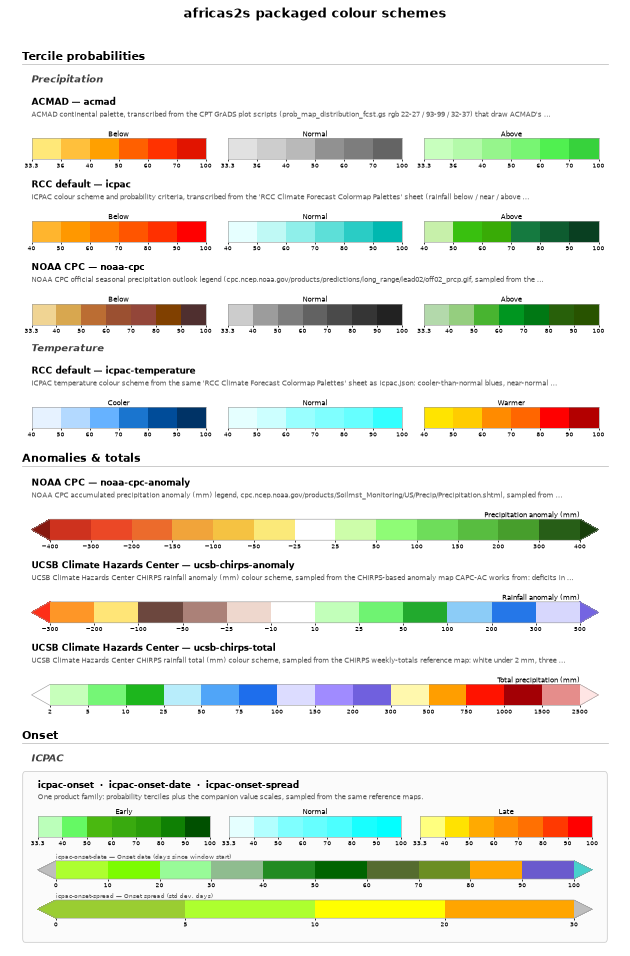

In [8]:
fig = africas2s.show_schemes()
fig.set_dpi(70)                     # display the reference sheet compactly
plt.show()

#### 1.6 What the raw models say

Before any calibration, each model's ensemble-mean ASO 2026 total is shown
as an **anomaly against that model's own ASO climatology**, so systematic
wet or dry bias cancels and what remains is the signal calibration will work
with — drawn on the packaged NOAA CPC precipitation-anomaly scale. Raw
totals would mostly redraw the Congo basin's climatology once per model; the
anomaly is the part that differs between models and between years. The
fields are the very `(hindcast, forecast)` pairs §2 calibrates, interpolated
from the wide CCA domain onto the ECCAS grid for display only.

model fields are in 'mm'; anomalies scaled by 1 to mm over the season


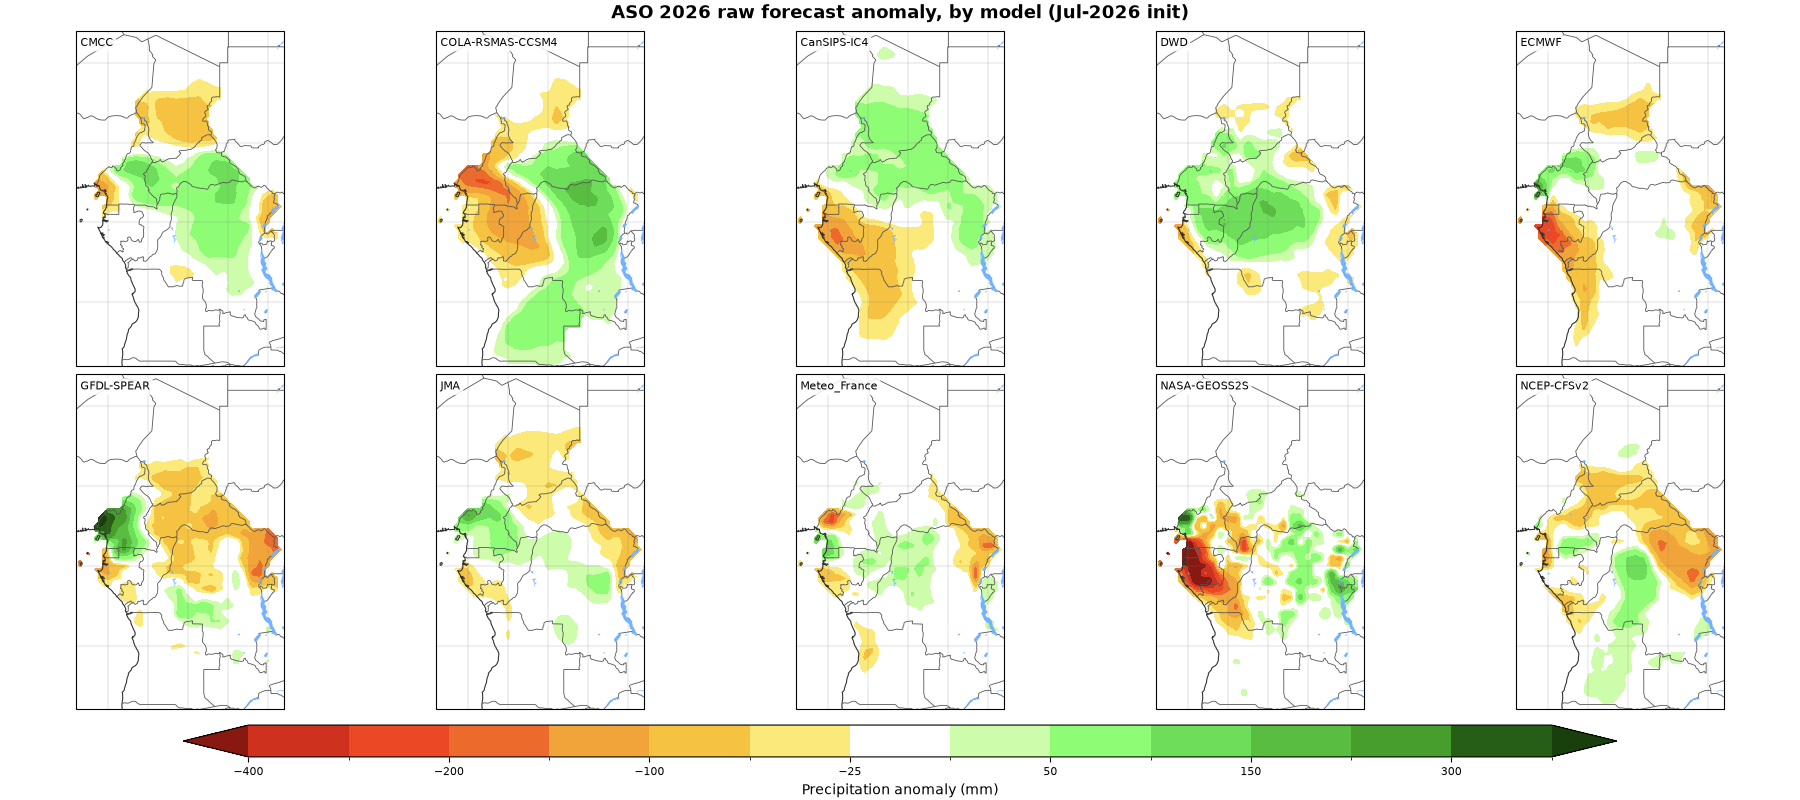

In [9]:
unit  = next(iter(models[SEASON].values()))[0].attrs.get("units")
scale = SEASON_DAYS if unit == "mm/day" else 1.0
print(f"model fields are in {unit!r}; anomalies scaled by {scale:g} to mm over the season")

grid = obs_lo[SEASON]
raw_anomalies = {}
for label, (hind, fcst) in sorted(models[SEASON].items()):
    f = scale * fcst.isel(year=0).mean("member").interp(lat=grid.lat, lon=grid.lon)
    c = scale * hind.mean("member").mean("year").interp(lat=grid.lat, lon=grid.lon)
    raw_anomalies[label] = f - c

africas2s.plot_matrix(
    raw_anomalies, style=STYLE_LO, ncols=5, smooth=3,
    scale=FieldScale.named("noaa-cpc-anomaly"),
    suptitle=f"ASO {YEAR} raw forecast anomaly, by model (Jul-{YEAR} init)",
    panel_size=(3.6, 4.0))
plt.savefig(FIG / "01_raw_anomaly_by_model.png", dpi=150)
plt.show()

### 2. CCA — pattern calibration, model by model

Where a per-cell regression treats every grid point independently, CCA works
with **whole spatial patterns**. Both fields are reduced to their leading
EOFs, then CCA finds weight vectors $(\mathbf{a}_k, \mathbf{b}_k)$
maximising

$$ \rho_k \;=\; \mathrm{corr}\big(\mathbf{a}_k^{\top}\mathbf{X},\;
   \mathbf{b}_k^{\top}\mathbf{Y}\big), \qquad \rho_1 \ge \rho_2 \ge \dots $$

with $\mathbf{X}$ the predictor — deliberately the **global tropics**
(30°S–30°N) model rainfall, so a remote Pacific- or Atlantic-sector pattern
that leads Central African rainfall can be exploited — and $\mathbf{Y}$
observed ECCAS rainfall. The forecast is reconstructed from the retained
modes, cross-validated, and turned into tercile probabilities through a
Student-t error model.

One CCA runs per model, window and resolution, so each model is calibrated
against its own hindcast record (`native_years=True`) and its probabilities
are built per model before combining (`probability_aggregation=
"cpt_per_model"`). The CCA settings follow common CPT practice: 7 X-EOFs, 7 Y-EOFs, 2 CCA modes, a 5-year cross-validation window, no
standardisation. Probabilities stay 0–1 throughout, on the integer 0/1/2
tercile coordinate `seasonal_mme` returns.

In [10]:
CCA_ARGS = dict(x_eof_modes=7, y_eof_modes=7, cca_modes=2,
                crossvalidation_window=5, standardize=False)

cca, cca_full = {}, {}
for w in WINDOWS:
    for rname, obs_w in (("0.5°", obs_lo[w]), ("10 km", obs_hi[w])):
        maps = {}
        for label, pair in sorted(models[w].items()):
            try:
                r = africas2s.seasonal_mme(
                    {"prcp": {label: pair}}, obs_w, method="cca",
                    native_years=True, probability_aggregation="cpt_per_model",
                    cpt_args=CCA_ARGS, forecast_year=YEAR, verbose=False)
            except Exception as e:
                print(f"[CCA dropped] {w} {rname} {label}: "
                      f"{type(e).__name__}: {str(e)[:90]}")
                continue
            maps[label] = r.tercile_forecast
            if w == SEASON and rname == "0.5°":
                cca_full[label] = r          # full result: §3 reads tercile_cv
        cca[(w, rname)] = maps
        print(f"{w} at {rname}: {len(maps)} calibrated models")

ASO at 0.5°: 10 calibrated models


ASO at 10 km: 10 calibrated models


SON at 0.5°: 10 calibrated models


SON at 10 km: 10 calibrated models


OND at 0.5°: 10 calibrated models


OND at 10 km: 10 calibrated models


#### 2.1 The calibrated models, first window

The per-model ASO 2026 maps at 10 km, after calibration. Comparing these
panels with the raw anomalies in §1.6 shows what calibration actually does:
it keeps the part of a model's signal that has historically tracked observed
rainfall and discards the rest, so the maps are typically quieter and closer to one another.
White cells are where no category qualifies as dominant under the CPC
display rule (a leading category needs the opposite tercile under 33 %).

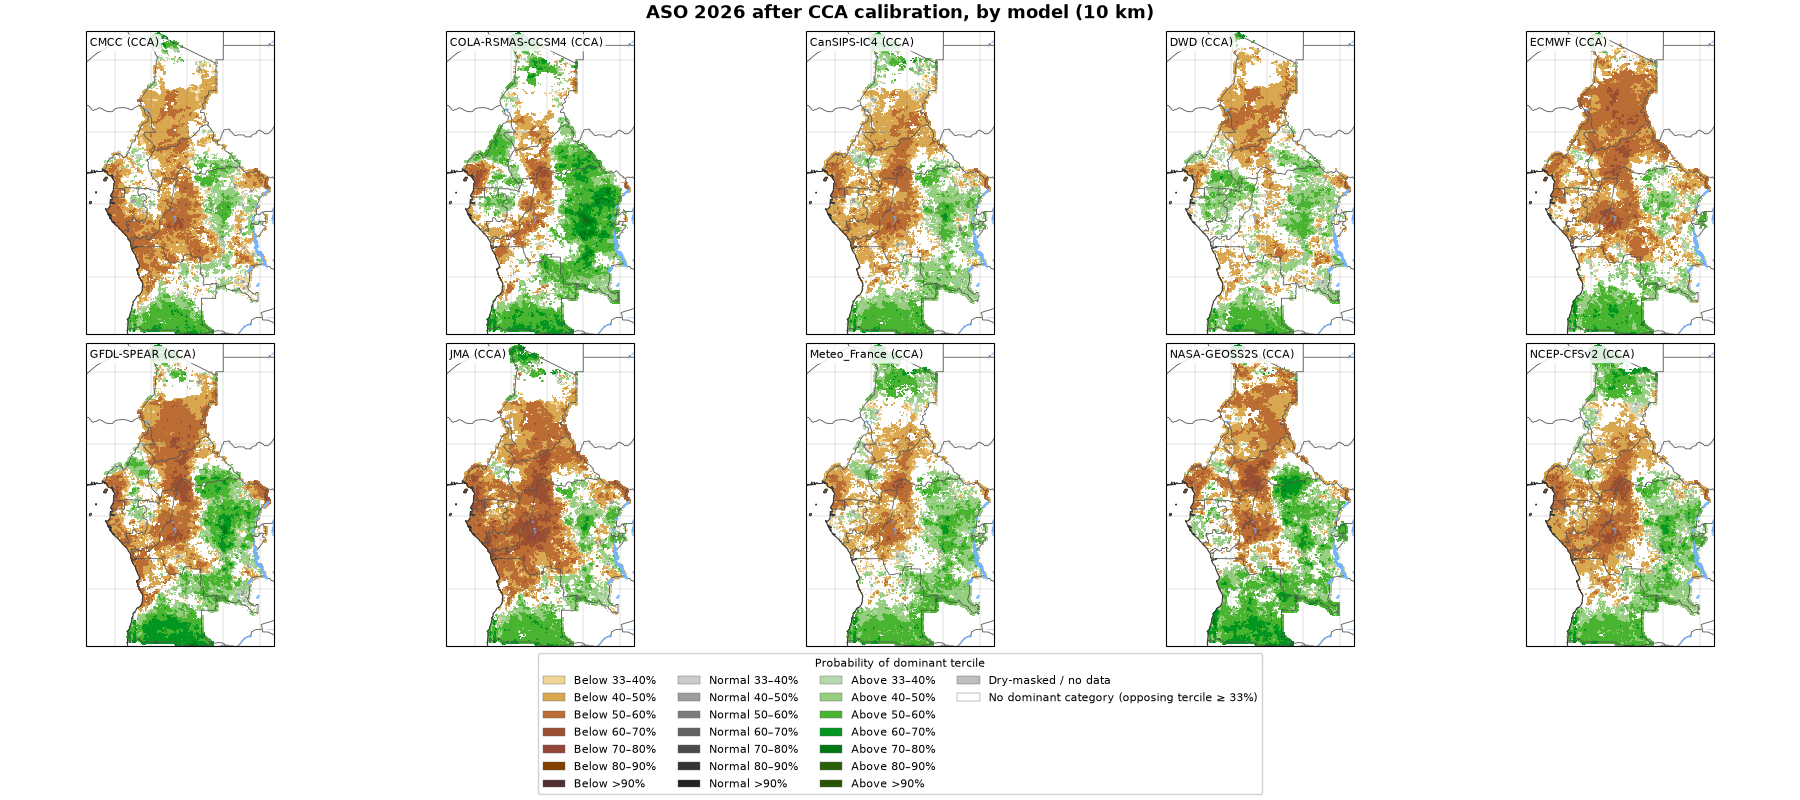

In [11]:
africas2s.plot_matrix(
    {f"{label} (CCA)": probs for label, probs in sorted(cca[(SEASON, "10 km")].items())},
    style=STYLE_HI, ncols=5, smooth=3, legend_detailed=True,
    suptitle=f"ASO {YEAR} after CCA calibration, by model (10 km)",
    panel_size=(3.6, 4.0))
plt.savefig(FIG / "02_cca_calibrated_by_model.png", dpi=150)
plt.show()

#### 2.2 The objective forecast

The equal-weight combination of the calibrated models,

$$ P_{\mathrm{obj}}(c \mid x) \;=\; \frac{1}{M}\sum_{m=1}^{M}
   P_m(c \mid x), \qquad
   c \in \{\text{below},\,\text{normal},\,\text{above}\} $$

renormalised onto the simplex, so each model gets one vote regardless of how
many ensemble members it carries. Averaging probabilities rather than
picking a winner is deliberately conservative: where the models disagree the
result relaxes toward climatology, and a confident tilt survives only where
they agree. The first window is shown at both working resolutions — the
high-resolution leg calibrates against 0.1° CHIRPS, which is precisely the
axis CCA can exploit: its reconstruction lives on the predictand grid, so
finer observations sharpen the map (skill remains bounded by the ~1°
predictors).

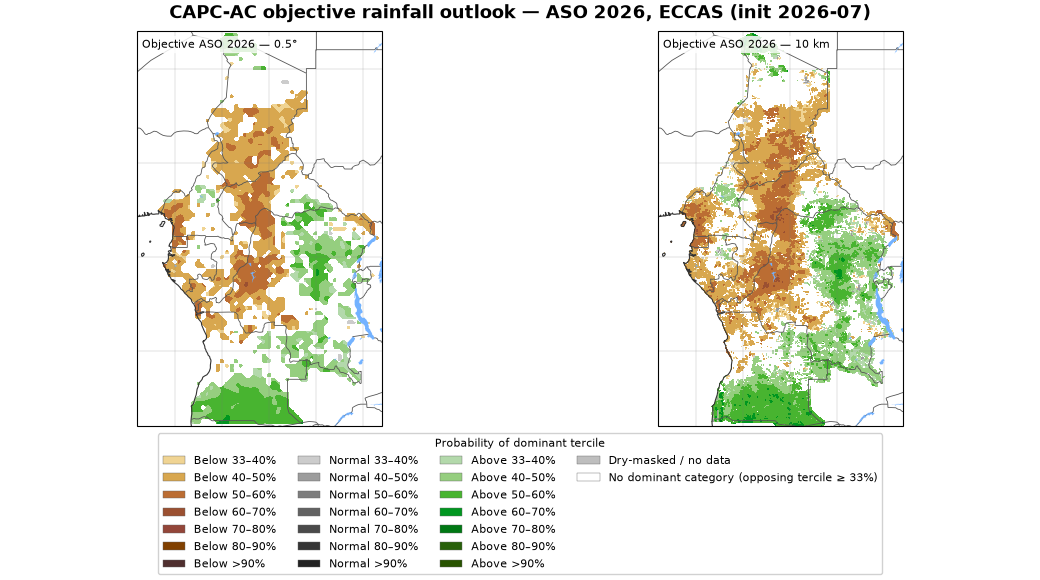

In [12]:
def combine(maps):
    o = xr.concat(list(maps.values()), "m").mean("m")
    return o / o.sum("tercile")

objective = {k: combine(v) for k, v in cca.items()}

africas2s.plot_matrix(
    [(f"Objective ASO {YEAR} — 0.5°", objective[(SEASON, "0.5°")]),
     (f"Objective ASO {YEAR} — 10 km", objective[(SEASON, "10 km")], STYLE_HI)],
    style=STYLE_LO, ncols=2, smooth=3, legend_detailed=True,
    suptitle=f"CAPC-AC objective rainfall outlook — ASO {YEAR}, ECCAS (init {INIT_MONTH})",
    panel_size=(5.2, 5.8))
plt.savefig(FIG / "03_objective_two_resolutions.png", dpi=150)
plt.show()

#### 2.3 Three windows, two resolutions

The same objective for every forecast window of this issuance — ASO, SON and
OND 2026, each at 0.5° and 10 km. Reading down the rows shows the forecast
evolve with lead time; reading across shows what the finer predictand adds.

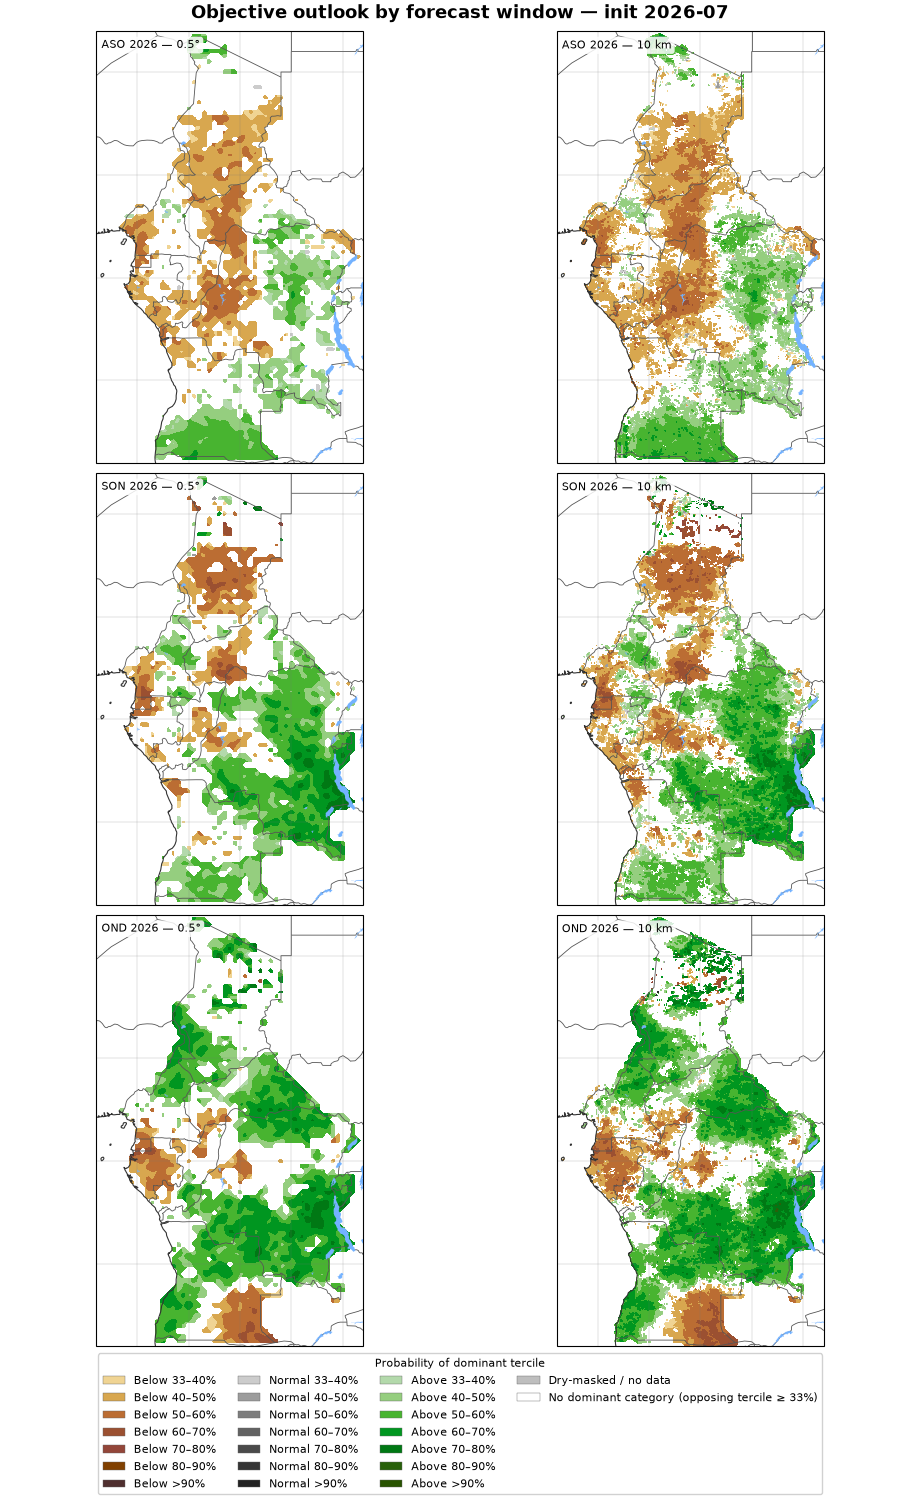

In [13]:
panels = []
for w in WINDOWS:
    panels.append((f"{w} {YEAR} — 0.5°", objective[(w, "0.5°")]))
    panels.append((f"{w} {YEAR} — 10 km", objective[(w, "10 km")], STYLE_HI))

africas2s.plot_matrix(
    panels, style=STYLE_LO, ncols=2, smooth=3, legend_detailed=True,
    suptitle=f"Objective outlook by forecast window — init {INIT_MONTH}",
    panel_size=(4.6, 5.0))
plt.savefig(FIG / "04_objective_windows_6panel.png", dpi=150)
plt.show()

### 3. Skill and expert adjustment

#### 3.1 Cross-validated per-model skill

How much should each model be trusted? The CCA pipeline keeps every model's
**cross-validated tercile hindcast** — each training year forecast with that
year (and its 5-year window) held out — and `africas2s.skill` scores it
against the observations, cell by cell: **GROC** (generalized ROC / 2AFC —
the probability the forecast ranks a wetter year above a drier one; 0.5 = no
discrimination) and **RPSS** (ranked-probability skill score against
climatology; > 0 beats climatology). Skill is assessed on the first window
at the 0.5° operational grid, where the cross-validated records live.

The model with the **lowest domain-mean GROC** is outlined in red — the
candidate an operational forecaster would examine first when curating the
roster.

In [14]:
skill_groc, skill_rpss, domain_groc = {}, {}, {}
for label, r in sorted(cca_full.items()):
    cv = r.tercile_cv
    o = obs_lo[SEASON].sel(year=cv.year.values)
    sk = africas2s.skill(cv, o, metrics=["rpss", "generalized_roc"], spatial=True)
    skill_groc[label] = sk.spatial["generalized_roc"]
    skill_rpss[label] = sk.spatial["rpss"]
    domain_groc[label] = sk.scores["generalized_roc"]

worst = min(domain_groc, key=domain_groc.get)
for label in sorted(domain_groc):
    flag = "   <- lowest domain-mean GROC" if label == worst else ""
    print(f"{label:18s} GROC {domain_groc[label]:.3f}{flag}")

CMCC               GROC 0.481
COLA-RSMAS-CCSM4   GROC 0.442   <- lowest domain-mean GROC
CanSIPS-IC4        GROC 0.473
DWD                GROC 0.444
ECMWF              GROC 0.475
GFDL-SPEAR         GROC 0.480
JMA                GROC 0.459
Meteo_France       GROC 0.453
NASA-GEOSS2S       GROC 0.463
NCEP-CFSv2         GROC 0.443


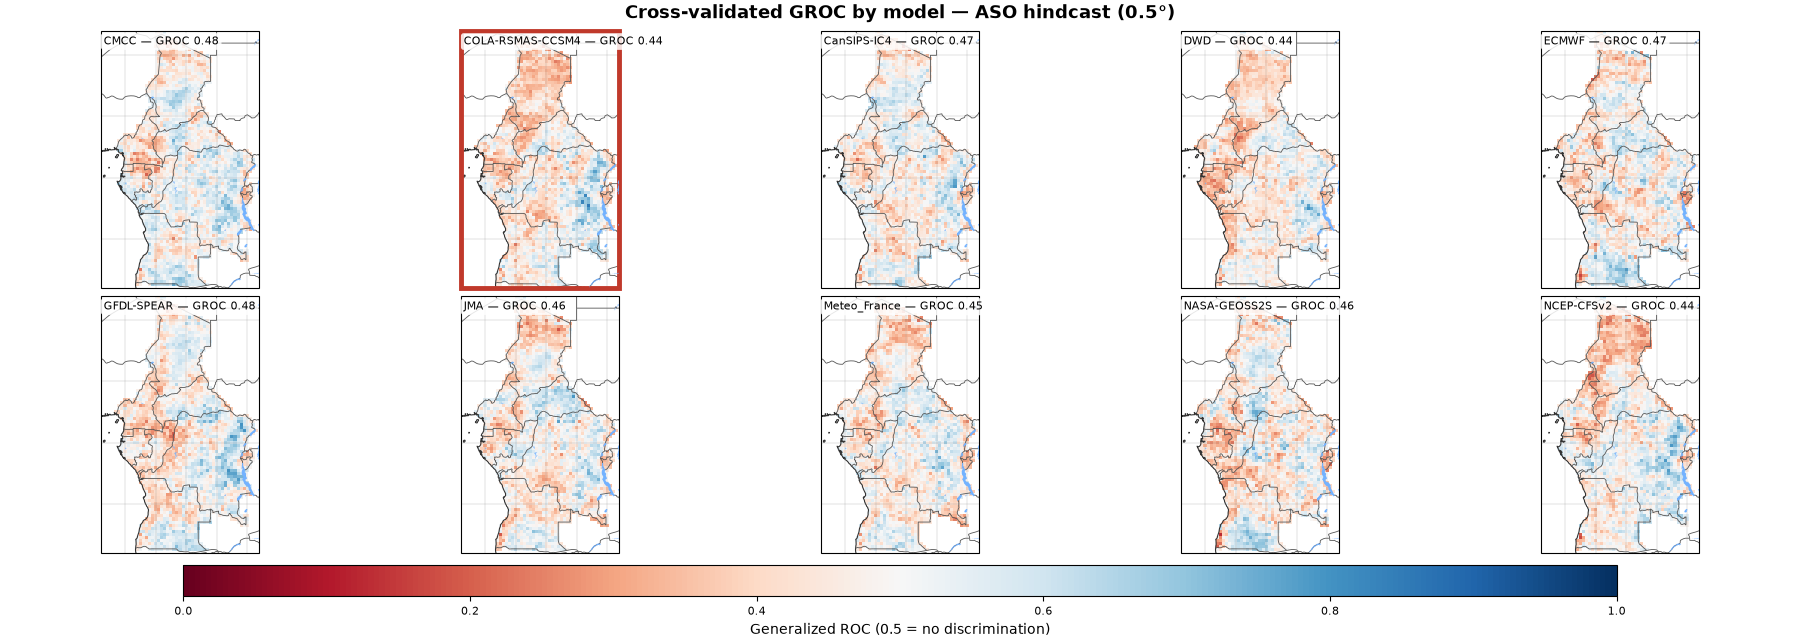

In [15]:
fig_groc = africas2s.plot_matrix(
    {f"{l} — GROC {domain_groc[l]:.2f}": m for l, m in sorted(skill_groc.items())},
    style=STYLE_LO, ncols=5, cmap="RdBu", vmin=0, vmax=1,
    cbar_label="Generalized ROC (0.5 = no discrimination)",
    suptitle=f"Cross-validated GROC by model — {SEASON} hindcast (0.5°)",
    panel_size=(3.6, 3.2))
ix = sorted(skill_groc).index(worst)
sp = fig_groc.axes[ix].spines["geo"]
sp.set_edgecolor("#c0392b"); sp.set_linewidth(3.5); sp.set_visible(True)
plt.savefig(FIG / "05_skill_groc_by_model.png", dpi=150)
plt.show()

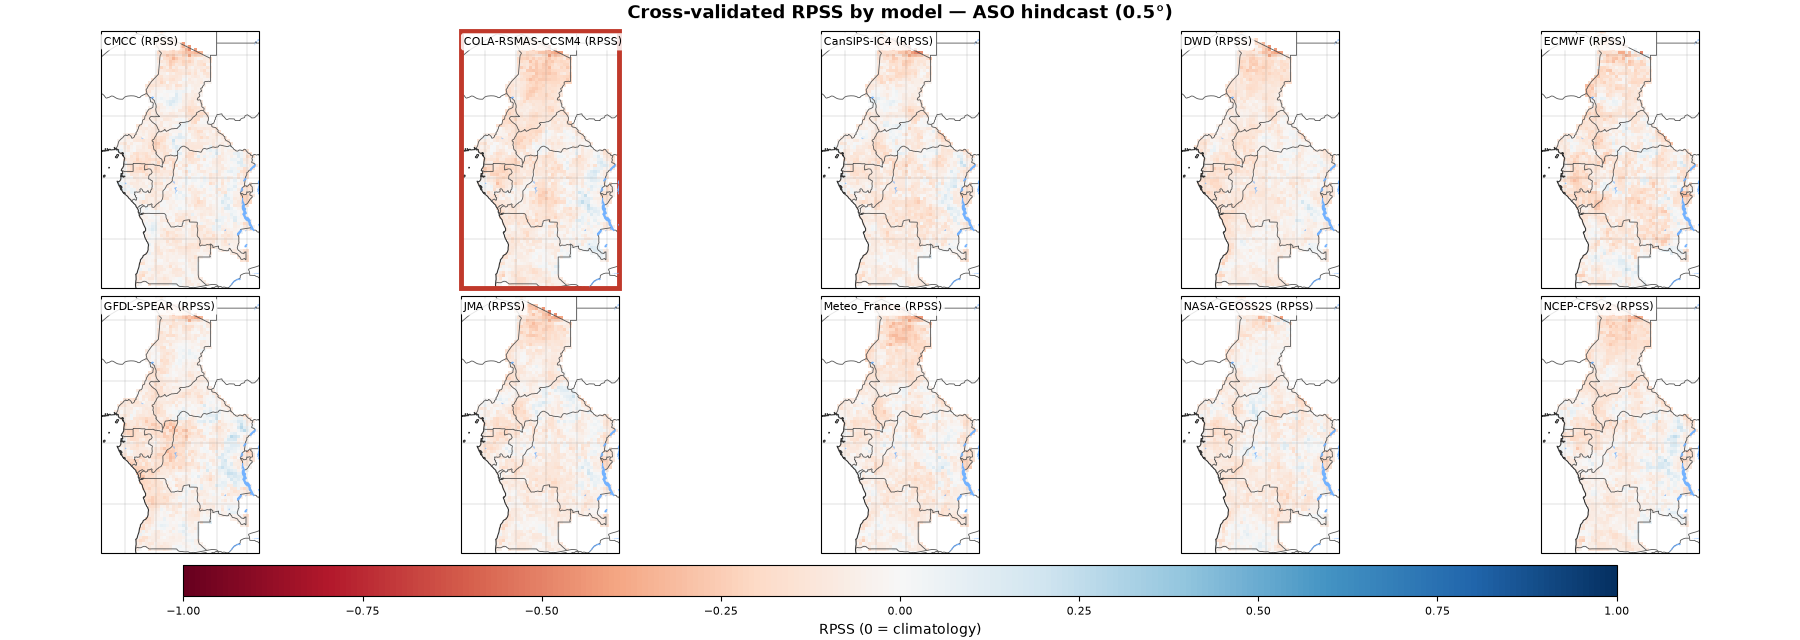

In [16]:
fig_rpss = africas2s.plot_matrix(
    {f"{l} (RPSS)": m for l, m in sorted(skill_rpss.items())},
    style=STYLE_LO, ncols=5, cmap="RdBu", vmin=-1, vmax=1,
    cbar_label="RPSS (0 = climatology)",
    suptitle=f"Cross-validated RPSS by model — {SEASON} hindcast (0.5°)",
    panel_size=(3.6, 3.2))
sp = fig_rpss.axes[ix].spines["geo"]
sp.set_edgecolor("#c0392b"); sp.set_linewidth(3.5); sp.set_visible(True)
plt.savefig(FIG / "06_skill_rpss_by_model.png", dpi=150)
plt.show()

#### 3.2 Re-combining without the lowest-skill model

Operational forecasters curate the roster every cycle. Because §2 kept each
model's **post-calibration map**, dropping a model is pure arithmetic on
maps already in memory: re-average the 10 km per-model forecasts without the
excluded model and renormalise — **no re-download, no re-calibration,
seconds of work**. The exclusion here follows the skill maps above (lowest
domain-mean GROC); the choice is the forecaster's. The third panel shows
where it matters: the change in P(above-normal), in percentage points.

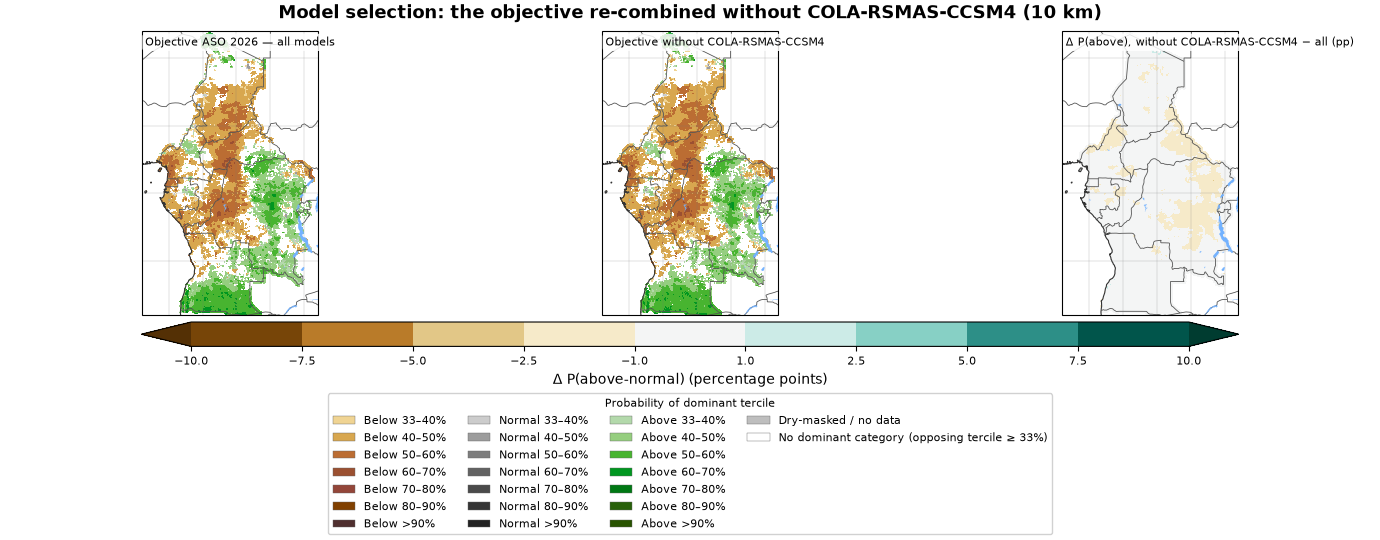

In [17]:
maps_hi  = cca[(SEASON, "10 km")]
obj_all  = objective[(SEASON, "10 km")]
obj_excl = combine({l: m for l, m in maps_hi.items() if l != worst})
diff_pp  = 100.0 * (obj_excl.sel(tercile=2) - obj_all.sel(tercile=2))

africas2s.plot_matrix(
    [(f"Objective ASO {YEAR} — all models", obj_all),
     (f"Objective without {worst}", obj_excl),
     (f"Δ P(above), without {worst} − all (pp)", diff_pp)],
    style=STYLE_HI, ncols=3, smooth=3, legend_detailed=True,
    levels=[-10, -7.5, -5, -2.5, -1, 1, 2.5, 5, 7.5, 10], cmap="BrBG",
    extend="both", cbar_label="Δ P(above-normal) (percentage points)",
    suptitle=f"Model selection: the objective re-combined without {worst} (10 km)",
    panel_size=(4.6, 5.4))
plt.savefig(FIG / "07_objective_without_lowest_skill.png", dpi=150)
plt.show()

### 4. Analogue years

An independent check on the objective forecast: which past years' El
Niño/La Niña evolution most resembles the run-up to this season? The
Niño3.4 series comes from ERSST v5 (anomalies against the 1991–2020 monthly
climatology, smoothed to overlapping 3-month means — the ONI convention);
the cell below cuts each year's twelve-season window at the same relative
point, and `africas2s.analogs_from_evolution` ranks every candidate year by temporal
correlation and mean absolute difference, composed. Because the ranking
never sees rainfall, only SST, the observed rainfall in the selected years
is a genuine out-of-sample check on the outlook above.

**The window is the twelve seasons ending at issuance.** Each year's
"evolution" is the run of twelve overlapping 3-month means that ends with the
**last season fully observed before the forecast was issued** — for this
1 July 2026 issuance, the season ending June 2026, i.e. **AMJ 2026**. The
target curve therefore spans MJJ 2025 ... AMJ 2026, and every candidate year
is cut at the same relative point.

Two properties make this the right window. It is **issuance-anchored and
leak-free** — nothing after June 2026 enters the ranking. And it is **always
twelve points**, which keeps the correlation meaningful: a window of only the
seasons elapsed in the target's own calendar year can be as few as five
points, too few for a correlation to separate candidates.

In [18]:
ersst = acmaddl.fetch("obs/ersst-v5", "sst", hindcast=(1981, 2026), verbose=False)["sst"]
nino = ersst.sel(lat=slice(-5, 5)).sel(lon=slice(190, 240)).mean(["lat", "lon"])
nino_anom = nino.groupby("time.month") - nino.sel(
    time=slice("1991-01-01", "2020-12-31")).groupby("time.month").mean("time")
oni = nino_anom.rolling(time=3, center=True).mean().dropna("time").rename("oni")

MON = ["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"]
N_STEPS = 12

# The anchor: the 3-month season whose LAST month is the month before issuance.
# A season is labelled by its centre month, so the anchor centre is init - 2.
_iy, _im = int(INIT_MONTH[:4]), int(INIT_MONTH[5:7])
ANCHOR_MONTH = (_im - 3) % 12 + 1
ANCHOR_YEAR = _iy if _im - 2 >= 1 else _iy - 1
LABELS = [MON[(ANCHOR_MONTH - 1 - (N_STEPS - 1) + k) % 12] for k in range(N_STEPS)]
ANCHOR_SST_MONTHS = [(ANCHOR_MONTH - 2) % 12 + 1, ANCHOR_MONTH, ANCHOR_MONTH % 12 + 1]

_oni_by_ym = {(int(t.dt.year), int(t.dt.month)): float(v)
              for t, v in zip(oni.time, oni.values)}

def evolution_curves(years, anchor_month, n=N_STEPS):
    """(year, step) ONI evolution: the n consecutive 3-month seasons ending at
    the season centred on `anchor_month` of each year."""
    rows = []
    for y in years:
        vals = []
        for k in range(n - 1, -1, -1):            # chronological, ending at the anchor
            m = anchor_month - k
            yy, mm = (y, m) if m >= 1 else (y - 1, m + 12)
            vals.append(_oni_by_ym.get((yy, mm), np.nan))
        rows.append(vals)
    return xr.DataArray(np.array(rows, dtype=float), dims=("year", "step"),
                        coords={"year": list(years), "step": np.arange(n)})

curves = evolution_curves(range(1982, ANCHOR_YEAR + 1), ANCHOR_MONTH)
print(f"Evolution window: {LABELS[0]} .. {LABELS[-1]}, ending {LABELS[-1]} "
      f"{ANCHOR_YEAR} — the last season fully observed before the "
      f"{INIT_MONTH} issuance ({int(np.isfinite(curves.sel(year=ANCHOR_YEAR)).sum())} "
      f"of {N_STEPS} seasons finite)")

N_ANALOGS = 4
analogs = africas2s.analogs_from_evolution(
    curves, target_year=ANCHOR_YEAR, n=N_ANALOGS,
    candidates=[int(y) for y in curves.year.values if y < ANCHOR_YEAR])
TOPN = [int(y) for y in analogs.years]
print("Top analogue years:", TOPN,
      {y: (round(analogs.metadata["r"][y], 2), round(analogs.metadata["mad"][y], 2))
       for y in TOPN})

Evolution window: MJJ .. AMJ, ending AMJ 2026 — the last season fully observed before the 2026-07 issuance (12 of 12 seasons finite)
Top analogue years: [1997, 2002, 2017, 2023] {1997: (0.96, 0.14), 2002: (0.96, 0.26), 2017: (0.9, 0.17), 2023: (0.9, 0.38)}


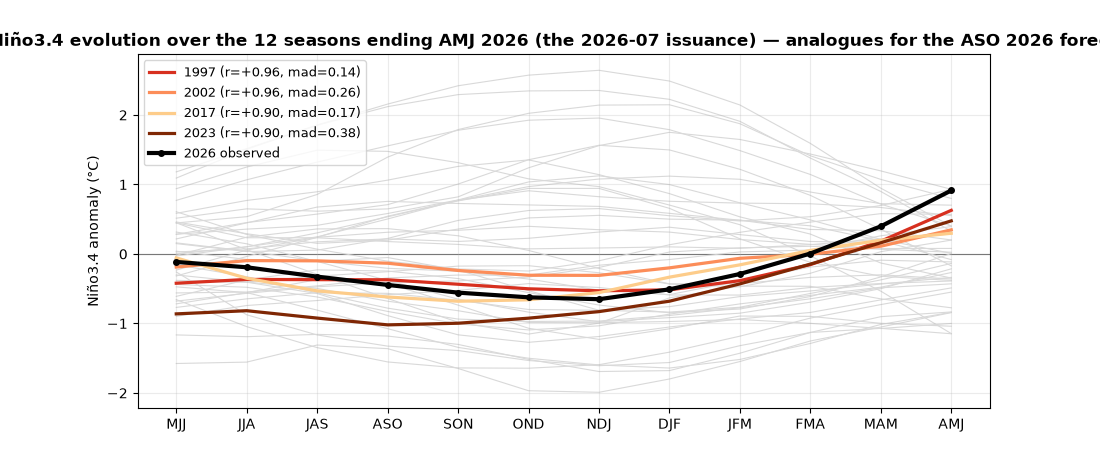

In [19]:
africas2s.plot_index_evolution(
    curves, analogs, labels=LABELS, ylabel="Niño3.4 anomaly (°C)",
    title=f"Niño3.4 evolution over the 12 seasons ending {LABELS[-1]} "
          f"{ANCHOR_YEAR} (the {INIT_MONTH} issuance) — "
          f"analogues for the ASO {YEAR} forecast")
plt.savefig(FIG / "08_nino34_analogue_plume.png", dpi=150)
plt.show()

#### The ocean state being matched, and its analogues

The curves above compress the tropical Pacific into one number per season;
the maps below are the patterns behind them. The **top panel is the state
being matched** — the anchor season, the last one fully observed before
issuance. The four beneath are the analogue years' patterns for the same
season, in rank order, each readable against the target directly: the
ranking is a correlation on the Niño3.4 *index*, and these maps show how
much of the broader pattern comes with it.

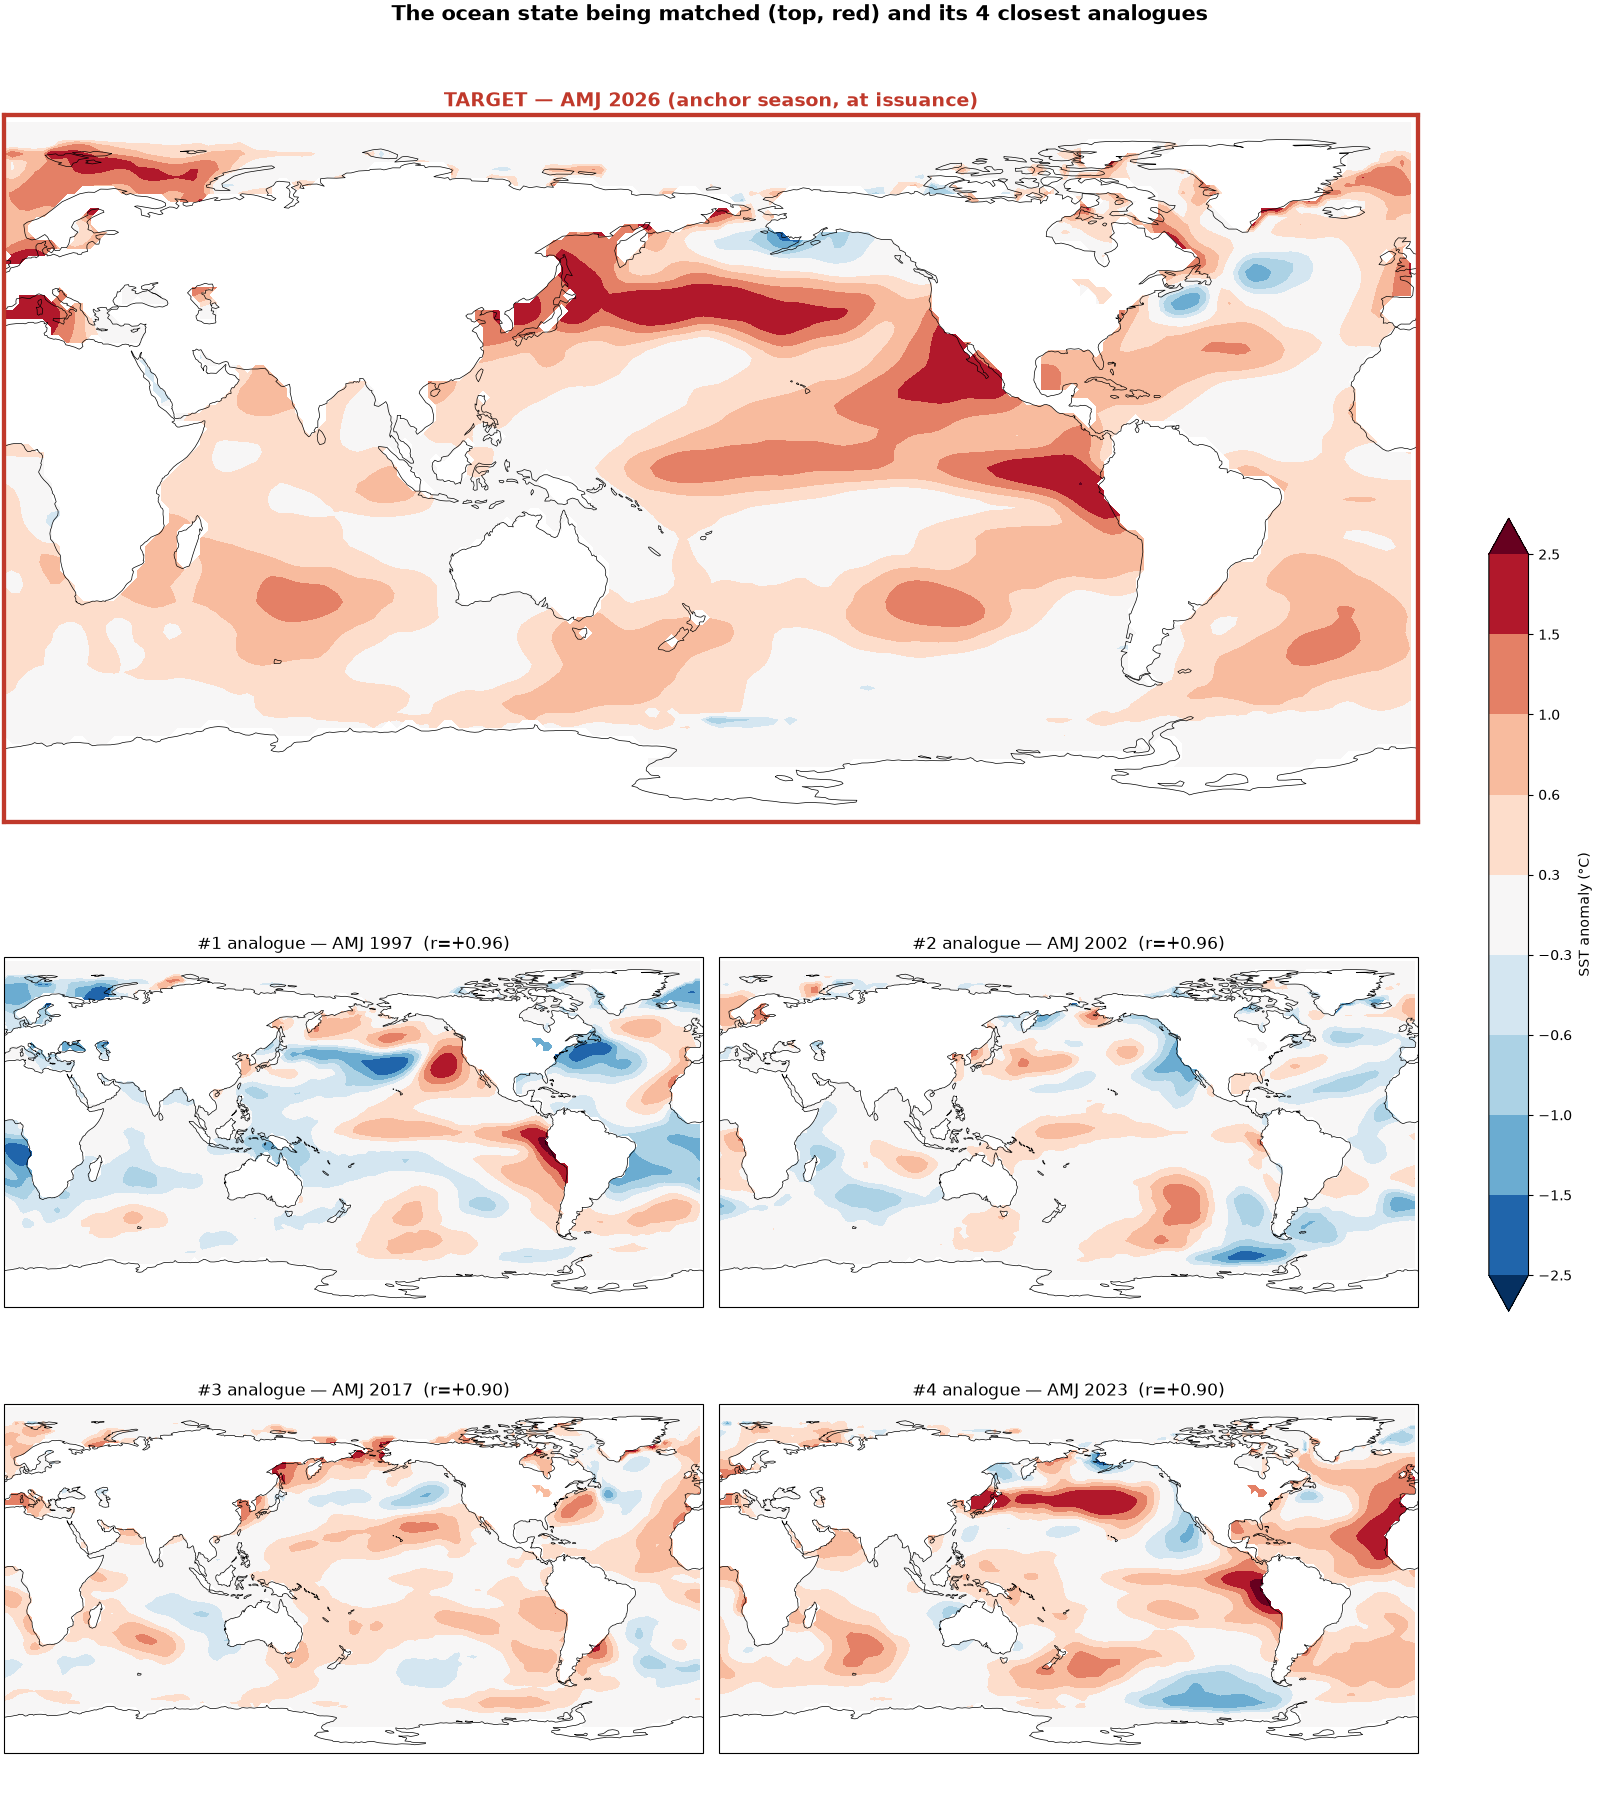

In [20]:
def season_sst_anom(months):
    """ERSST anomaly composite for a set of calendar months, vs 1991-2020."""
    f = ersst.sel(time=ersst.time.dt.month.isin(months)).groupby("time.year").mean("time")
    return f - f.sel(year=slice(1991, 2020)).mean("year")

sst_anchor = season_sst_anom(ANCHOR_SST_MONTHS)
SST_LEVELS = [-2.5, -1.5, -1.0, -0.6, -0.3, 0.3, 0.6, 1.0, 1.5, 2.5]

# Target on top at full width (height_ratios gives row 0 the room a 2:1
# global map needs to fill it), the four analogues beneath.
fig = plt.figure(figsize=(16, 18), layout="constrained")
gs = fig.add_gridspec(3, 2, height_ratios=[2, 1, 1])
proj = ccrs.PlateCarree(central_longitude=180)

def _sst_panel(ax, fld, title, target=False):
    cs = ax.contourf(fld.lon, fld.lat, fld.values, transform=ccrs.PlateCarree(),
                     levels=SST_LEVELS, cmap="RdBu_r", extend="both")
    ax.coastlines(lw=0.5); ax.set_global()
    ax.set_title(title, fontsize=14 if target else 12,
                 fontweight="bold" if target else "normal",
                 color="#c0392b" if target else "black")
    if target:
        for sp in ax.spines.values():
            sp.set_edgecolor("#c0392b"); sp.set_linewidth(3.0); sp.set_visible(True)
    return cs

ax_t = fig.add_subplot(gs[0, :], projection=proj)
ax_t.set_anchor("C")                      # centre it within the spanned row
cs = _sst_panel(ax_t, sst_anchor.sel(year=ANCHOR_YEAR),
                f"TARGET — {LABELS[-1]} {ANCHOR_YEAR} (anchor season, at issuance)",
                target=True)
for k, y in enumerate(TOPN):
    ax = fig.add_subplot(gs[1 + k // 2, k % 2], projection=proj)
    _sst_panel(ax, sst_anchor.sel(year=y),
               f"#{k + 1} analogue — {LABELS[-1]} {y}  "
               f"(r={analogs.metadata['r'][y]:+.2f})")
fig.colorbar(cs, ax=fig.axes, shrink=0.45, label="SST anomaly (°C)")
fig.suptitle(f"The ocean state being matched (top, red) and its {N_ANALOGS} "
             f"closest analogues", fontsize=15, fontweight="bold")
plt.savefig(FIG / "09_analogue_sst_patterns.png", dpi=150)
plt.show()

#### Observed outcomes in the analogue years, beside the objective forecast


For each analogue year, the observed rainfall tercile at every cell against
the 1991–2020 boundaries. A year either fell in a tercile or it did not — a
categorical field. Each observed panel is drawn at one representative shade
from its RCC category ramp, held at mid intensity so the outcomes sit
alongside the forecast rather than shouting past it.

The **first panel is this notebook's objective forecast**, shown as its
leading tercile so all five panels are read the same way. Agreement is corroboration from a line of
evidence that never saw rainfall; disagreement is a question worth asking
before the forecast goes out.

fetched CHIRPS ASO for the analogue year(s) [2023]


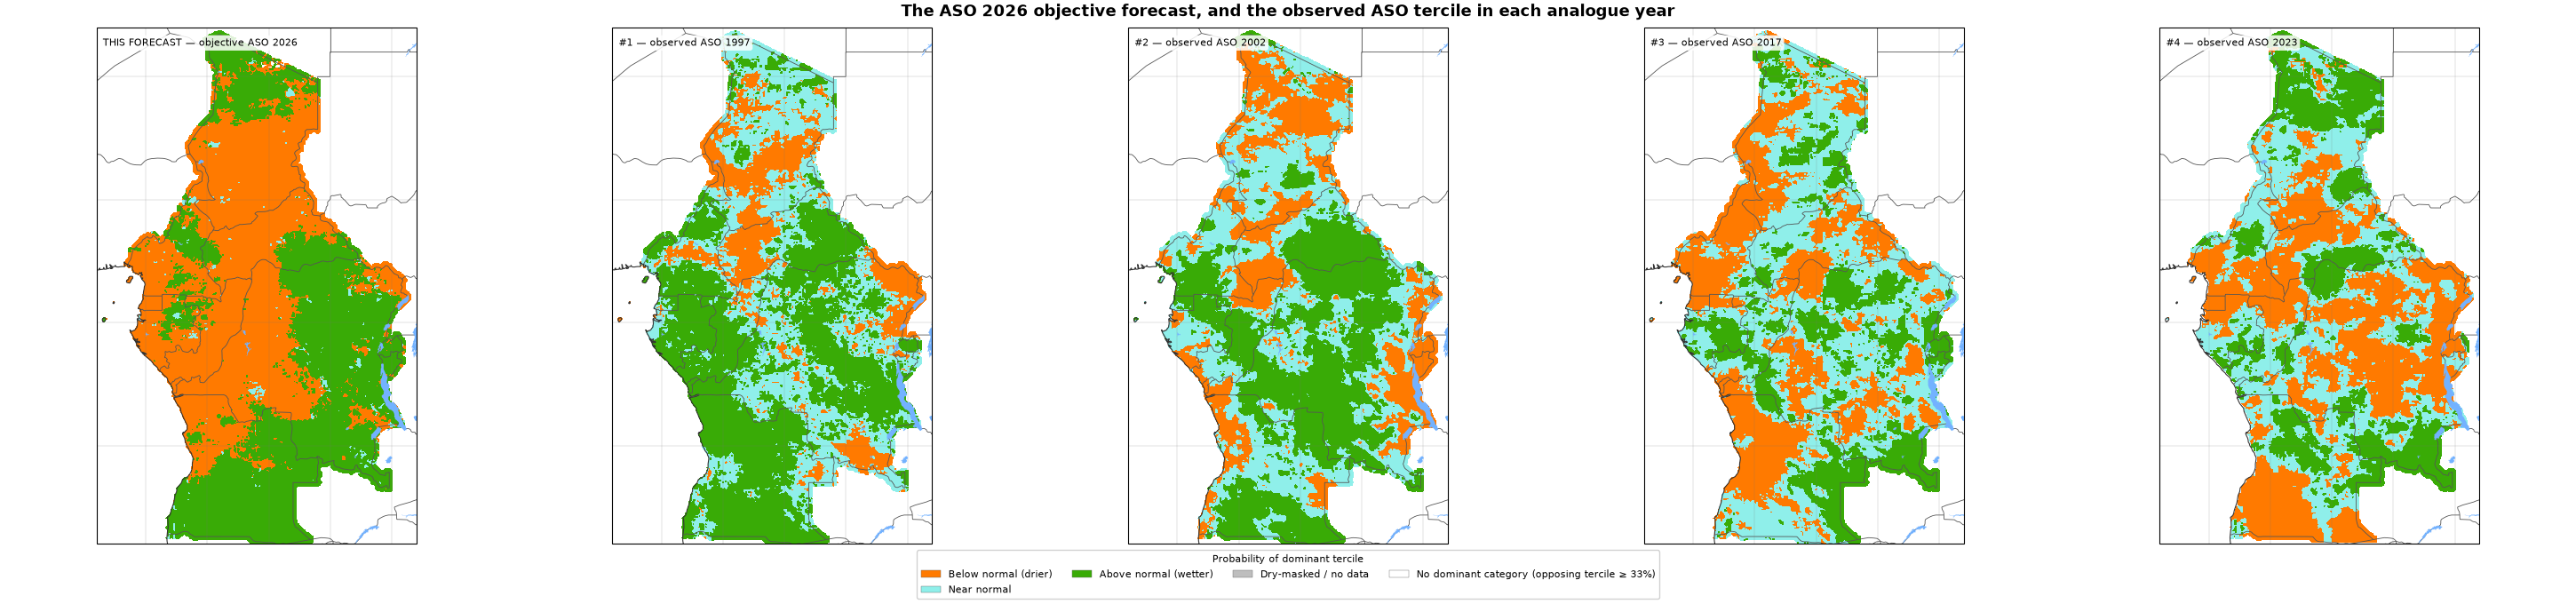

In [21]:
obs_rec = obs_hi[SEASON]
q1 = obs_rec.sel(year=slice(1991, 2020)).quantile(1 / 3, "year").drop_vars("quantile")
q2 = obs_rec.sel(year=slice(1991, 2020)).quantile(2 / 3, "year").drop_vars("quantile")

extra = [y for y in TOPN if y not in set(int(v) for v in obs_rec["year"].values)]
if extra:
    try:
        more = acmaddl.fetch("obs/chirps-v2-monthly", "precip", target=SEASON,
                             region=list(ECCAS_REGION), hindcast=(min(extra), max(extra)),
                             seasonal="mean", grid_res=RES_HI, boundary="cover",
                             verbose=False)["precip"]
        obs_rec = xr.concat([obs_rec, more.interp(lat=obs_rec.lat, lon=obs_rec.lon)], "year")
        print(f"fetched CHIRPS {SEASON} for the analogue year(s) {extra}")
    except Exception as e:
        print(f"NOTE: could not fetch CHIRPS for analogue year(s) {extra}: "
              f"{type(e).__name__}: {str(e)[:80]}")

# One representative shade per category (the 60-70 % band of each RCC ramp).
# A one-hot observed field is 100 % in its category, so on the full
# probability ramp it would land in the top band and read as an extreme
# forecast rather than a recorded outcome.
CAT_STYLE = replace(STYLE_HI, below_colors=["#FF7A00"], normal_colors=["#8FEFEA"],
                    above_colors=["#39AB06"], prob_bins=[33.3, 100.01])

have_years = set(int(v) for v in obs_rec["year"].values)
# The forecast rendered the way an observed outcome is: its leading tercile,
# one-hot. That makes all five panels categorical and directly comparable —
# "which way does the forecast lean" against "which way did it actually go".
# The probabilistic view, with its no-dominant-category white, is earlier in
# the notebook.
def dominant_onehot(probs):
    valid = np.isfinite(probs).all("tercile")
    lead = probs.fillna(-1.0).argmax("tercile")
    oh = xr.concat([(lead == k).astype(float) for k in range(3)], "tercile")
    return oh.assign_coords(tercile=[0, 1, 2]).where(valid)

panels = [(f"THIS FORECAST — objective ASO {YEAR}",
           dominant_onehot(objective[(SEASON, "10 km")]))]
for rank, y in enumerate(TOPN, 1):
    if y not in have_years:
        print(f"NOTE: analogue year {y} lies outside the available CHIRPS record "
              f"({min(have_years)}-{max(have_years)}).")
        continue
    f = obs_rec.sel(year=y)
    below, above = f < q1, f > q2
    onehot = xr.concat([below, ~below & ~above, above], "tercile").astype(float)
    panels.append((f"#{rank} — observed {SEASON} {y}",
                   onehot.assign_coords(tercile=[0, 1, 2]).where(np.isfinite(f)),
                   CAT_STYLE))

africas2s.plot_matrix(
    panels, style=CAT_STYLE, ncols=len(panels), smooth=3,
    suptitle=f"The ASO {YEAR} objective forecast, and the observed "
             f"{SEASON} tercile in each analogue year",
    panel_size=(5.8, 6.8))
plt.savefig(FIG / "10_observed_terciles_analogue_years.png", dpi=150)
plt.show()

### 5. Onset of the rains

When the season *starts* matters as much as how much falls. Onset is
computed from the **daily** C3S forecasts with `africas2s.aggregations`,
using the library's default onset criterion (the ICPAC/GHACOF definition):
**20 mm accumulated over 3 days**, rejected if a
7-day dry spell follows within the next 21 days. The search window is the
season's three months plus the following month — **1 August to 30 November**
— so neither an early onset nor a late one is clipped; the daily data are
fetched one month further (into December) for the dry-spell guard.

Five C3S systems issue daily fields from the same July initialisation; each
is fetched on its 1° grid, its onset computed member by member, and the
members pooled into one ensemble (a system whose daily fields are not
available is dropped with the reason printed). The observed climatology
applies the identical criterion to daily CHIRPS v3 (the Rhiza mirror,
2005–2024, 0.25°, the same months). Maps are drawn at each product's
**native grid** — no interpolation — with the packaged ICPAC onset colour
schemes (`icpac-onset-date`, `icpac-onset-spread`). **White cells are an
honest signal, not a mask**: no qualifying onset in at least half the
members (forecast) or years (climatology).

In [22]:
DAILY_MODELS = [("ECMWF", "c3s/ecmwf"), ("Meteo_France", "c3s/meteofrance-daily"),
                ("CMCC", "c3s/cmcc-sps4-daily"), ("DWD", "c3s/dwd-daily"),
                ("ECCC", "c3s/eccc-daily")]
ONSET_SEASON, ONSET_FETCH = "ASON", "ASOND"   # search 1 Aug - 30 Nov; data into Dec
ONSET_START = dt.date(YEAR, 8, 1)

pooled, used, offset = [], [], 0
for label, product in DAILY_MODELS:
    try:
        daily = acmaddl.fetch(product, "precip", init=INIT_MONTH, target=ONSET_FETCH,
                              region=list(ECCAS_REGION), hindcast=(YEAR, YEAR),
                              grid_res=1.0, verbose=False)["precip"]
        daily = (daily.squeeze("init_time", drop=True)
                      .swap_dims({"lead_time": "time"}).clip(min=0))
        step = agg.onset(daily, season=ONSET_SEASON).step.squeeze("year", drop=True)
        step = step.assign_coords(member=np.arange(offset, offset + step.sizes["member"]))
        offset += step.sizes["member"]
        pooled.append(step)
        used.append(f"{label} ({step.sizes['member']}m)")
    except Exception as e:
        print(f"[onset dropped] {label}: {type(e).__name__}: {str(e)[:110]}")

assert pooled, "no daily onset models available — check CDS credentials / licences"
onset_ens = xr.concat(pooled, dim="member")
print(f"onset ensemble: {onset_ens.sizes['member']} members — " + ", ".join(used))

chirps_daily = acmaddl.fetch("obs/chirps-v3-daily-rhiza", "precip",
                             region=list(ECCAS_REGION), hindcast=(2005, 2024),
                             months=[8, 9, 10, 11, 12], grid_res=0.25,
                             verbose=False)["precip"]
obs_onset = agg.onset(chirps_daily, season=ONSET_SEASON)

onset ensemble: 222 members — ECMWF (51m), Meteo_France (51m), CMCC (50m), DWD (50m), ECCC (20m)


  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


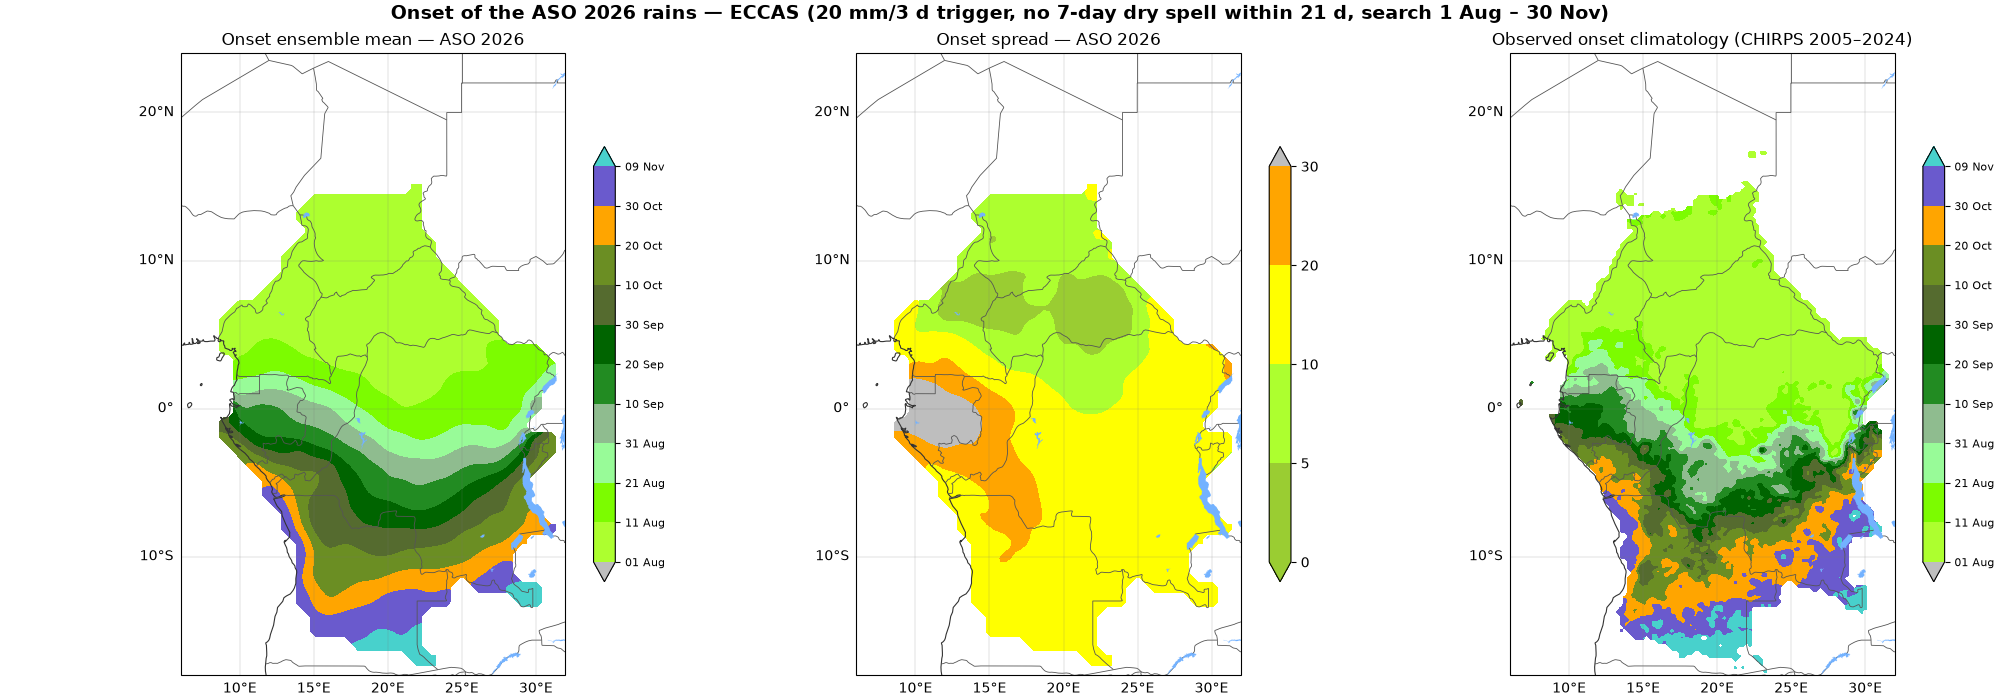

In [23]:
DATE_SCALE = FieldScale.named("icpac-onset-date")
step_to_date = lambda t: (ONSET_START + dt.timedelta(days=int(t))).strftime("%d %b")

frac = onset_ens.notnull().mean("member")
panels = [
    (onset_ens.mean("member").where(frac >= 0.5), DATE_SCALE,
     f"Onset ensemble mean — ASO {YEAR}"),
    (onset_ens.std("member").where(frac >= 0.5), FieldScale.named("icpac-onset-spread"),
     f"Onset spread — ASO {YEAR}"),
    (obs_onset.step.mean("year").where(obs_onset.occurred.mean("year") >= 0.5), DATE_SCALE,
     "Observed onset climatology (CHIRPS 2005–2024)"),
]
fig, axes = plt.subplots(1, 3, figsize=(20, 7), layout="constrained",
                         subplot_kw={"projection": ccrs.PlateCarree()})
for ax, (fld, sc, ttl) in zip(axes, panels):
    im = africas2s.plot_field(fld, ax=ax, style=STYLE_HI, smooth=3, scale=sc, title=ttl)
    cb = fig.colorbar(im, ax=ax, shrink=0.7) if im is not None else None
    if cb is not None and sc is DATE_SCALE:
        cb.set_ticks(sc.levels)
        cb.set_ticklabels([step_to_date(t) for t in sc.levels], fontsize=8)
fig.suptitle(f"Onset of the ASO {YEAR} rains — ECCAS (20 mm/3 d trigger, no 7-day dry "
             "spell within 21 d, search 1 Aug – 30 Nov)", fontsize=14, fontweight="bold")
plt.savefig(FIG / "11_onset_mean_spread_climatology.png", dpi=150)
plt.show()